In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from google.colab import files
import io

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# 1. Cargar datos de manera interactiva
print("Por favor, sube tu archivo 'housing.csv':")
uploaded = files.upload()

# Obtener el nombre del archivo subido
file_name = list(uploaded.keys())[0]
data = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset shape:", data.shape)

data.head()

Por favor, sube tu archivo 'dataset_estacion.csv':


Saving housing.csv to housing (2).csv
Dataset loaded successfully!
Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


About this file

Suggest Edits
1. longitude: A measure of how far west a house is; a higher value is farther west

2. latitude: A measure of how far north a house is; a higher value is farther north

3. housingMedianAge: Median age of a house within a block; a lower number is a newer building

4. totalRooms: Total number of rooms within a block

5. totalBedrooms: Total number of bedrooms within a block

6. population: Total number of people residing within a block

7. households: Total number of households, a group of people residing within a home unit, for a block

8. medianIncome: Median income for households within a block of houses (measured in tens of thousands of US Dollars)

9. medianHouseValue: Median house value for households within a block (measured in US Dollars)

10. oceanProximity: Location of the house w.r.t ocean/sea

In [ ]:
# Display the last five rows

data.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
# Display statistical summary of numerical columns

data.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [ ]:
# Check missing values in each column

data.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [ ]:
data["total_bedrooms"].fillna(
    data["total_bedrooms"].median(),
    inplace=True
)

data.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


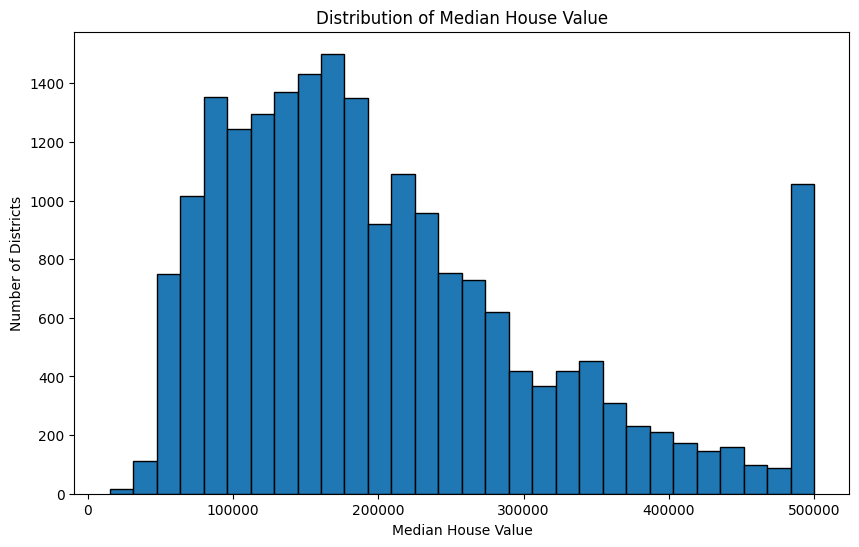

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    data["median_house_value"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Number of Districts")

plt.show()

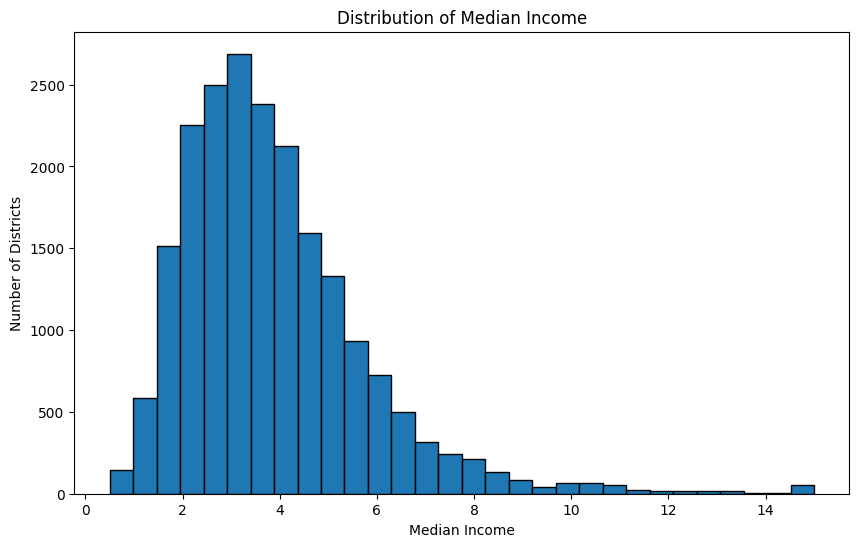

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    data["median_income"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Median Income")
plt.xlabel("Median Income")
plt.ylabel("Number of Districts")

plt.show()

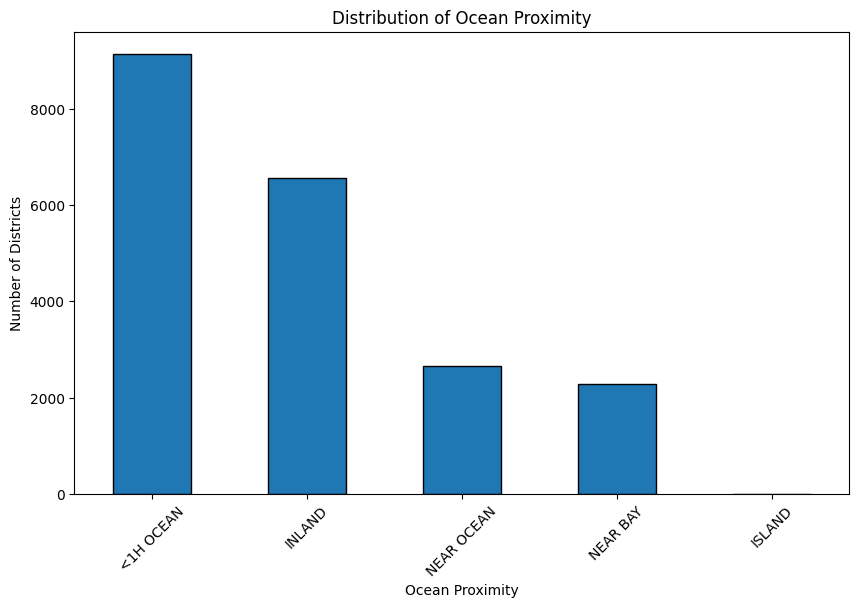

In [ ]:
data["ocean_proximity"].value_counts().plot(
    kind="bar",
    figsize=(10, 6),
    edgecolor="black"
)

plt.title("Distribution of Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Number of Districts")

plt.xticks(rotation=45)
plt.show()

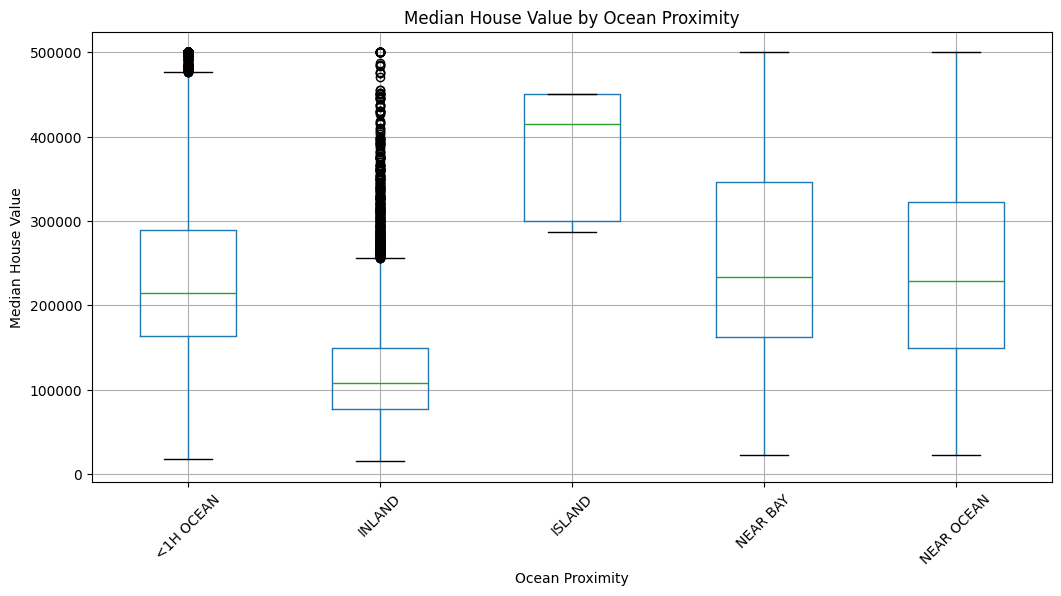

In [ ]:
data.boxplot(
    column="median_house_value",
    by="ocean_proximity",
    figsize=(12, 6)
)

plt.title("Median House Value by Ocean Proximity")
plt.suptitle("")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value")

plt.xticks(rotation=45)
plt.show()

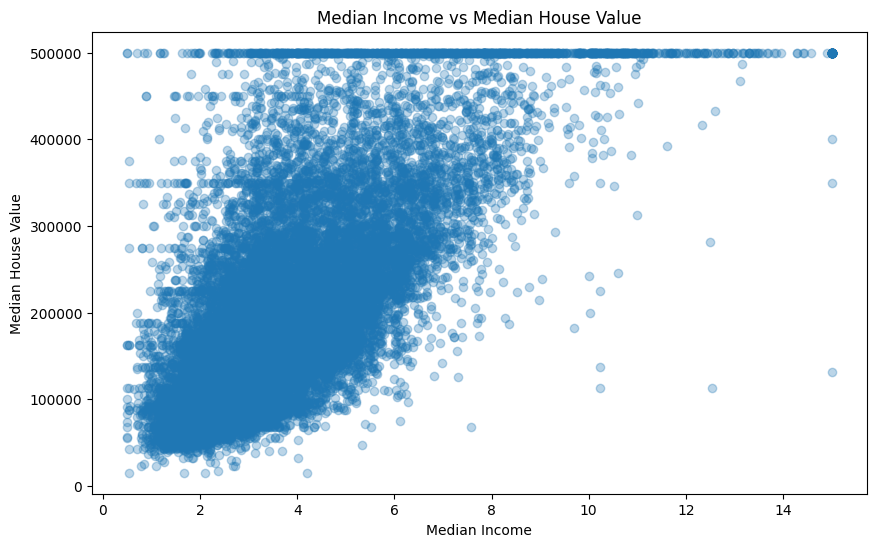

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    data["median_income"],
    data["median_house_value"],
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

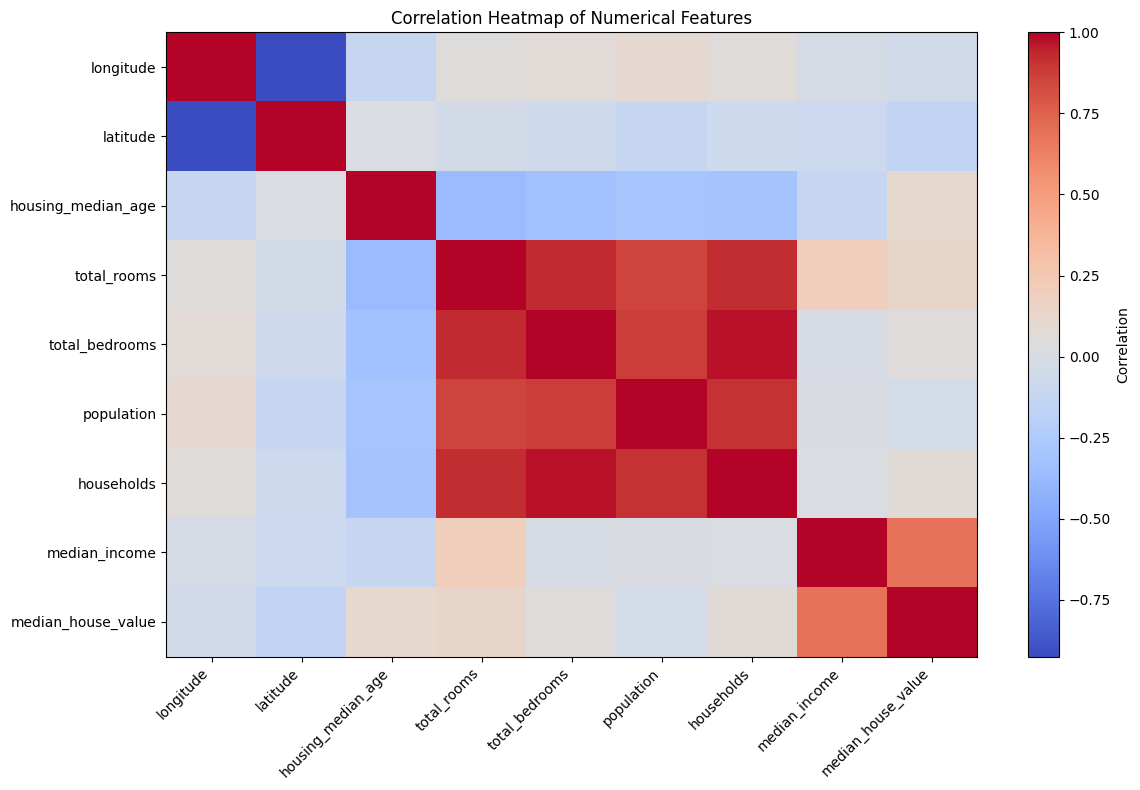

In [ ]:
correlation = data.select_dtypes(
    include=["int64", "float64"]
).corr()

plt.figure(figsize=(12, 8))

plt.imshow(
    correlation,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

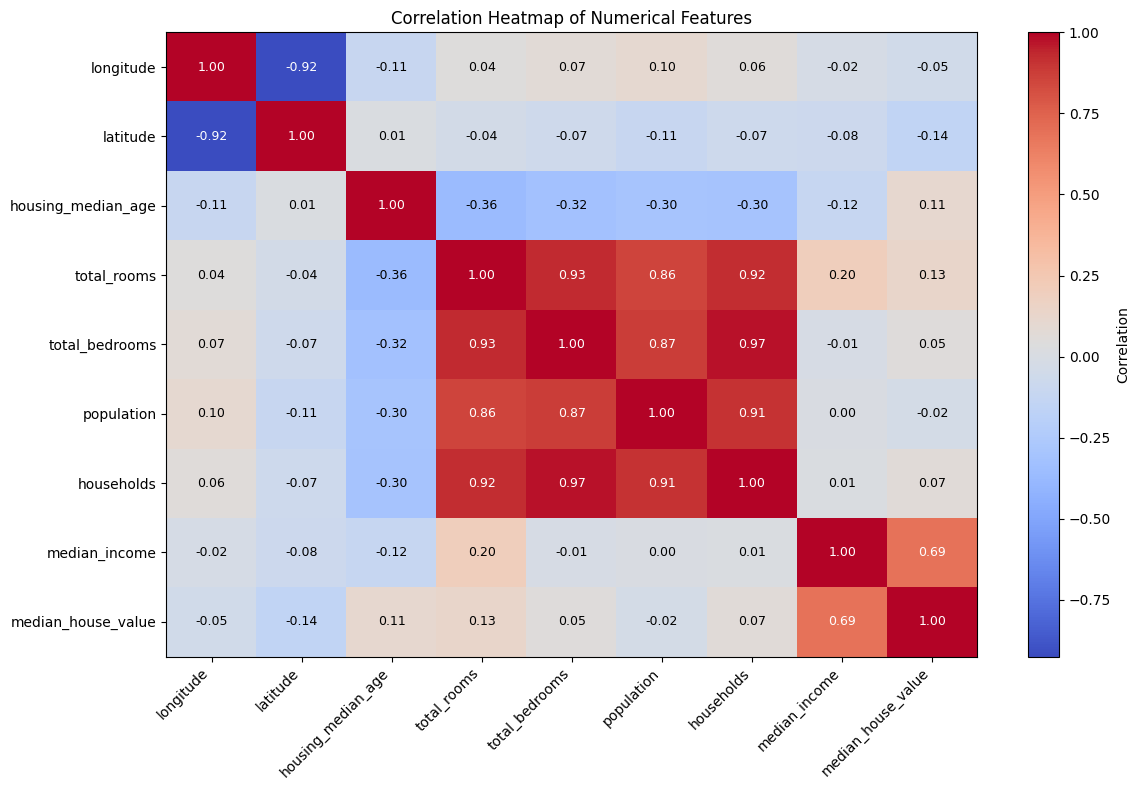

In [ ]:
correlation = data.select_dtypes(include=["int64", "float64"]).corr()

plt.figure(figsize=(12, 8))

plt.imshow(correlation, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Correlation")

# --- NUEVO: Mostrar el valor numérico en cada celda ---
for i in range(len(correlation.columns)):
  for j in range(len(correlation.columns)):
    val = correlation.iloc[i, j]
    # Si el color de fondo es muy oscuro, ponemos texto blanco; si es claro, negro
    color = "white" if abs(val) > 0.5 else "black"
    plt.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=9)

plt.xticks(
    range(len(correlation.columns)), correlation.columns, rotation=45, ha="right"
)

plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

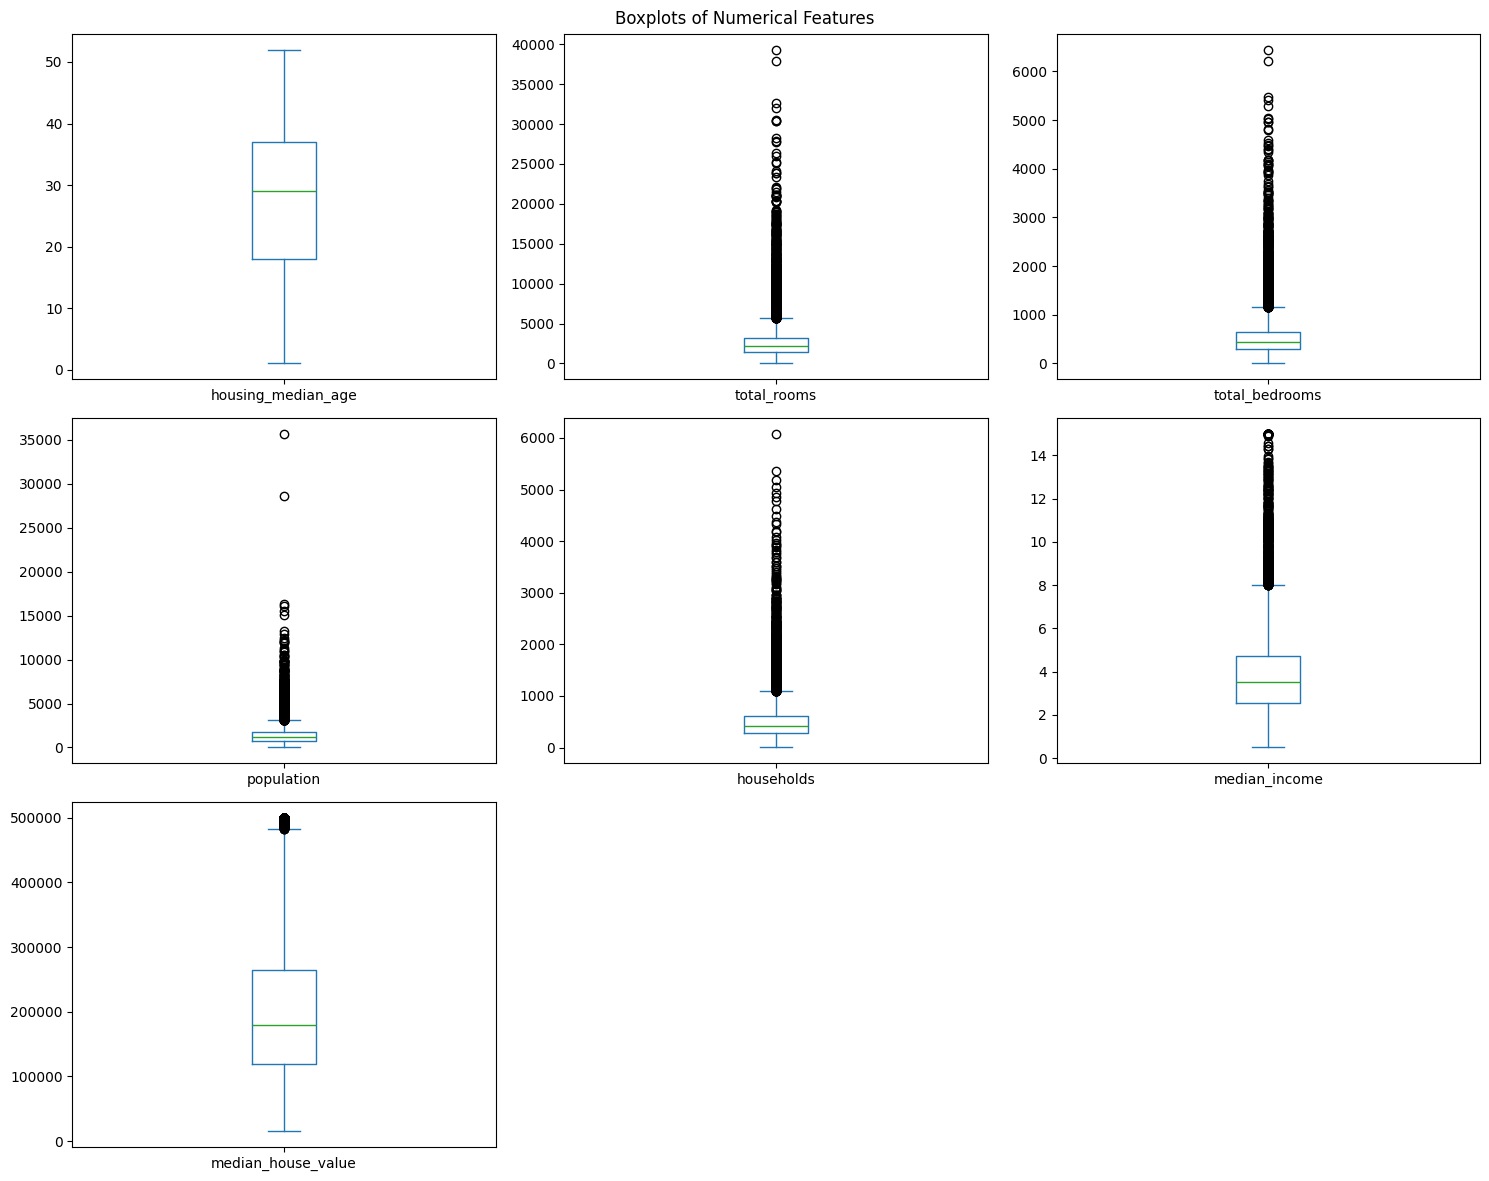

In [ ]:
numerical_columns = [
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
    "median_house_value"
]

data[numerical_columns].plot(
    kind="box",
    subplots=True,
    layout=(3, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.suptitle("Boxplots of Numerical Features")

plt.tight_layout()
plt.show()

In [ ]:
data["rooms_per_household"] = (
    data["total_rooms"] / data["households"]
)

data["bedrooms_per_room"] = (
    data["total_bedrooms"] / data["total_rooms"]
)

data["population_per_household"] = (
    data["population"] / data["households"]
)

data[
    [
        "rooms_per_household",
        "bedrooms_per_room",
        "population_per_household"
    ]
].head()

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467


In [ ]:
print("Updated dataset shape:", data.shape)

data.info()

Updated dataset shape: (20640, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20640 non-null  float64
 1   latitude                  20640 non-null  float64
 2   housing_median_age        20640 non-null  float64
 3   total_rooms               20640 non-null  float64
 4   total_bedrooms            20640 non-null  float64
 5   population                20640 non-null  float64
 6   households                20640 non-null  float64
 7   median_income             20640 non-null  float64
 8   median_house_value        20640 non-null  float64
 9   ocean_proximity           20640 non-null  object 
 10  rooms_per_household       20640 non-null  float64
 11  bedrooms_per_room         20640 non-null  float64
 12  population_per_household  20640 non-null  float64
dtypes: float64(12), object(1)


In [ ]:
print("Final dataset shape:", data.shape)

print("Total missing values:", data.isnull().sum().sum())

print("Total duplicate rows:", data.duplicated().sum())

data.head()

Final dataset shape: (20640, 13)
Total missing values: 0
Total duplicate rows: 0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467


In [ ]:
data.to_csv(
    "california_housing_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
data.to_csv(
    "california_housing_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
# Convert categorical data into numerical columns

data = pd.get_dummies(
    data,
    columns=["ocean_proximity"],
    drop_first=False,
    dtype=int
)

data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,6.984127,0.146591,2.555556,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,6.238137,0.155797,2.109842,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,8.288136,0.129516,2.802260,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,5.817352,0.184458,2.547945,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,6.281853,0.172096,2.181467,0,0,0,1,0


# Definís el diccionario de reemplazo
mapeo = {
    "<1H OCEAN": 0,
    "INLAND": 1,
    "NEAR BAY": 2,
    "NEAR OCEAN": 3,
    "ISLAND": 4,
}

# Reemplazas la columna directamente en el DataFrame
data["ocean_proximity"] = data["ocean_proximity"].map(mapeo)

data.head()

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   20640 non-null  float64
 1   latitude                    20640 non-null  float64
 2   housing_median_age          20640 non-null  float64
 3   total_rooms                 20640 non-null  float64
 4   total_bedrooms              20640 non-null  float64
 5   population                  20640 non-null  float64
 6   households                  20640 non-null  float64
 7   median_income               20640 non-null  float64
 8   median_house_value          20640 non-null  float64
 9   rooms_per_household         20640 non-null  float64
 10  bedrooms_per_room           20640 non-null  float64
 11  population_per_household    20640 non-null  float64
 12  ocean_proximity_<1H OCEAN   20640 non-null  int64  
 13  ocean_proximity_INLAND      206

In [ ]:
print("Updated dataset shape:", data.shape)

print("\nDataset columns:")

data.columns

Updated dataset shape: (20640, 17)

Dataset columns:


Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'rooms_per_household', 'bedrooms_per_room',
       'population_per_household', 'ocean_proximity_<1H OCEAN',
       'ocean_proximity_INLAND', 'ocean_proximity_ISLAND',
       'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN'],
      dtype='object')

In [ ]:
X = data.drop(
    "median_house_value",
    axis=1
)

y = data[
    "median_house_value"
]

print("Independent variables shape:", X.shape)

print("Dependent variable shape:", y.shape)

Independent variables shape: (20640, 16)
Dependent variable shape: (20640,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (16512, 16)
X_test shape: (4128, 16)
y_train shape: (16512,)
y_test shape: (4128,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print("Feature scaling completed successfully!")

print("X_train_scaled shape:", X_train_scaled.shape)

print("X_test_scaled shape:", X_test_scaled.shape)

Feature scaling completed successfully!
X_train_scaled shape: (16512, 16)
X_test_scaled shape: (4128, 16)


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(
    X_train_scaled,
    y_train
)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
# Predict house values using the test data

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")

# Display the first 10 actual and predicted values

comparison = pd.DataFrame({
    "Actual Value": y_test.values[:10],
    "Predicted Value": y_pred[:10]
})

comparison

Predictions generated successfully!


,Actual Value,Predicted Value
0,47700.0,61463.744666
1,45800.0,121631.218100
2,500001.0,267594.253891
3,218600.0,264252.963820
4,278000.0,258213.789828
5,158700.0,151805.134515
6,198200.0,308380.085708
7,157500.0,243588.672418
8,340000.0,257766.450671
9,446600.0,410596.381660


In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

mae = mean_absolute_error(
    y_test,
    y_pred
)

r2 = r2_score(
    y_test,
    y_pred
)

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("Mean Absolute Error:", mae)

print("R-squared Score:", r2)

Mean Squared Error: 5280716470.094015
Root Mean Squared Error: 72668.53837868225
Mean Absolute Error: 50888.66001572008
R-squared Score: 0.5970176824350764


In [ ]:
n = X_test.shape[0]

p = X_test.shape[1]

adjusted_r2 = 1 - (
    (1 - r2) * (n - 1)
    / (n - p - 1)
)

print("R-squared Score:", r2)

print("Adjusted R-squared Score:", adjusted_r2)

R-squared Score: 0.5970176824350764
Adjusted R-squared Score: 0.5954492764314181


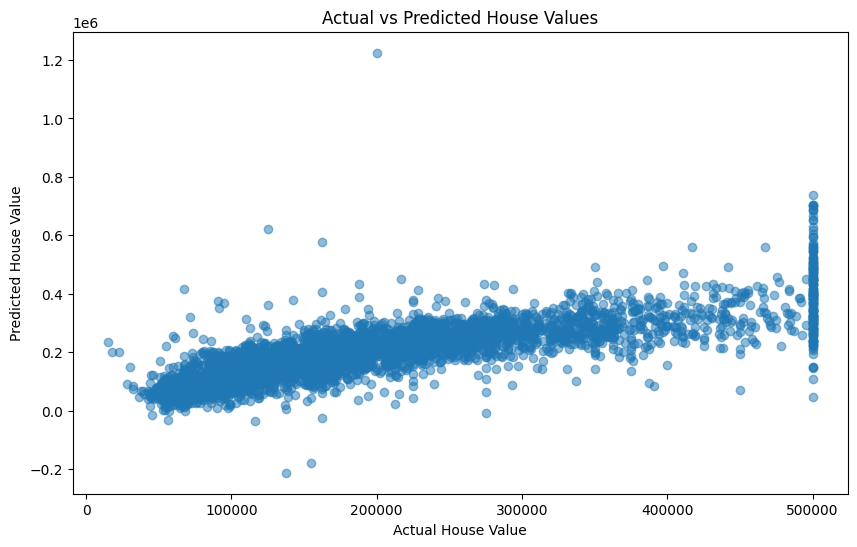

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.xlabel("Actual House Value")

plt.ylabel("Predicted House Value")

plt.title(
    "Actual vs Predicted House Values"
)

plt.show()

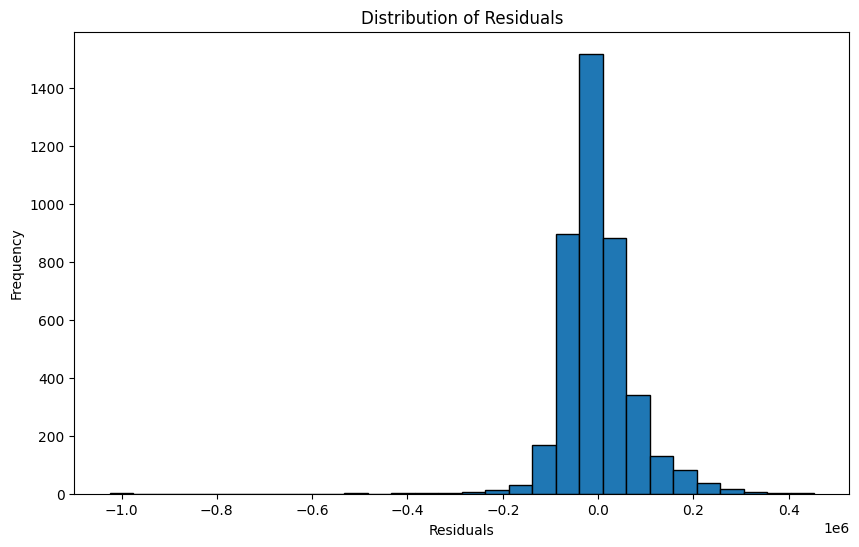

In [ ]:
# Calculate residuals

residuals = y_test - y_pred

# Plot residual distribution

plt.figure(figsize=(10, 6))

plt.hist(
    residuals,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Residuals")

plt.ylabel("Frequency")

plt.title(
    "Distribution of Residuals"
)

plt.show()

In [ ]:
train_r2 = model.score(
    X_train_scaled,
    y_train
)

test_r2 = model.score(
    X_test_scaled,
    y_test
)

print("Training R-squared Score:", train_r2)

print("Testing R-squared Score:", test_r2)

Training R-squared Score: 0.6582199160539229
Testing R-squared Score: 0.5970176824350764


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

ridge = Ridge(alpha=1.0)

ridge.fit(X_train_scaled, y_train)

ridge_pred = ridge.predict(X_test_scaled)

ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression")
print("MAE :", ridge_mae)
print("MSE :", ridge_mse)
print("RMSE:", ridge_rmse)
print("R²  :", ridge_r2)

Ridge Regression
MAE : 50888.32333618049
MSE : 5280394346.134177
RMSE: 72666.32195270501
R²  : 0.5970422643759197


In [ ]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.01)

lasso.fit(X_train_scaled, y_train)

lasso_pred = lasso.predict(X_test_scaled)

lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)
lasso_r2 = r2_score(y_test, lasso_pred)

print("Lasso Regression")
print("MAE :", lasso_mae)
print("MSE :", lasso_mse)
print("RMSE:", lasso_rmse)
print("R²  :", lasso_r2)

Lasso Regression
MAE : 50888.6549778045
MSE : 5280714393.663994
RMSE: 72668.52409168631
R²  : 0.5970178408917151


In [ ]:
model = LinearRegression()

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train_scaled, y_train)

LinearRegression()

In [ ]:
# Linear Regression Evaluation

linear_pred = model.predict(X_test_scaled)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_mse = mean_squared_error(y_test, linear_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print("MAE :", linear_mae)
print("MSE :", linear_mse)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)

Linear Regression
MAE : 50888.66001572008
MSE : 5280716470.094015
RMSE: 72668.53837868225
R²  : 0.5970176824350764


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        linear_mae,
        ridge_mae,
        lasso_mae
    ],
    "MSE": [
        linear_mse,
        ridge_mse,
        lasso_mse
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse
    ],
    "R²": [
        linear_r2,
        ridge_r2,
        lasso_r2
    ]
})

comparison

,Model,MAE,MSE,RMSE,R²
0,Linear Regression,50888.660016,5.280716e+09,72668.538379,0.597018
1,Ridge Regression,50888.323336,5.280394e+09,72666.321953,0.597042
2,Lasso Regression,50888.654978,5.280714e+09,72668.524092,0.597018


In [ ]:
from sklearn.ensemble import RandomForestRegressor  # o RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

In [ ]:
# 1. Instanciar el modelo
rf_model = RandomForestRegressor(random_state=42)

# 2. ⚠️ ENTRENAR EL MODELO PRIMERO (Esto es lo que faltaba)
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

# 3. Ahora sí, generar predicciones con el conjunto de prueba
y_pred = rf_model.predict(X_test)

# 4. Calcular y mostrar las métricas
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"--- MÉTRICAS DEL RANDOM FOREST ---")
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Random Forest trained successfully!
--- MÉTRICAS DEL RANDOM FOREST ---
MAE: $32,338.27
RMSE: $50,382.99
R² Score: 0.8063


In [ ]:
import xgboost as xgb
import re

# Limpiar los nombres de las columnas de X_train y X_test reemplazando [, ], < y otros símbolos
X_train.columns = [
    re.sub(r"[\[\]<]", "", col) for col in X_train.columns
]
X_test.columns = [re.sub(r"[\[\]<]", "", col) for col in X_test.columns]

# (Opcional) Si también querés reemplazar espacios por guiones bajos para mayor prolijidad:
X_train.columns = [col.replace(" ", "_") for col in X_train.columns]
X_test.columns = [col.replace(" ", "_") for col in X_test.columns]

print("✅ Nombres de columnas limpios y aptos para XGBoost.")

# 1. Instanciar el modelo XGBoost
xgb_model = xgb.XGBRegressor(
    random_state=42
)

# 2. Entrenar el modelo con los datos de entrenamiento
xgb_model.fit(X_train, y_train)

# 3. Generar predicciones con el conjunto de prueba
y_pred = xgb_model.predict(X_test)

# 4. Calcular y mostrar las métricas de regresión
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"--- MÉTRICAS DE XGBOOST ---")
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

✅ Nombres de columnas limpios y aptos para XGBoost.
--- MÉTRICAS DE XGBOOST ---
MAE: $30,587.41
RMSE: $46,744.94
R² Score: 0.8333


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import xgboost as xgb
import numpy as np

# ==========================================
# 1. RANDOM FOREST + GRID SEARCH
# ==========================================
print("⏳ Buscando mejores hiperparámetros para Random Forest...")
rf = RandomForestRegressor(random_state=42)
rf_params = {
    'n_estimators': [50, 100],
    'max_depth': [10, None],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(rf, rf_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_

# Predicciones y Métricas RF
y_pred_rf = best_rf.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)


# ==========================================
# 2. XGBOOST + GRID SEARCH
# ==========================================
print("⏳ Buscando mejores hiperparámetros para XGBoost...")
xgb_model = xgb.XGBRegressor(random_state=42)
xgb_params = {
    'n_estimators': [50, 100],
    'max_depth': [3, 6],
    'learning_rate': [0.05, 0.1]
}

xgb_grid = GridSearchCV(xgb_model, xgb_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
xgb_grid.fit(X_train, y_train)
best_xgb = xgb_grid.best_estimator_

# Predicciones y Métricas XGBoost
y_pred_xgb = best_xgb.predict(X_test)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)


# ==========================================
# 3. MOSTRAR RESULTADOS COMPARATIVOS
# ==========================================
print("\n" + "="*50)
print("📊 RESULTADOS FINALES DE REGRESIÓN")
print("="*50)

print("\n🟢 Random Forest:")
print(f"   Mejores parámetros: {rf_grid.best_params_}")
print(f"   - MAE  : ${mae_rf:,.2f}")
print(f"   - RMSE : ${rmse_rf:,.2f}")
print(f"   - R²   : {r2_rf:.4f}")

print("\n🔵 XGBoost:")
print(f"   Mejores parámetros: {xgb_grid.best_params_}")
print(f"   - MAE  : ${mae_xgb:,.2f}")
print(f"   - RMSE : ${rmse_xgb:,.2f}")
print(f"   - R²   : {r2_xgb:.4f}")

⏳ Buscando mejores hiperparámetros para Random Forest...
⏳ Buscando mejores hiperparámetros para XGBoost...

📊 RESULTADOS FINALES DE REGRESIÓN

🟢 Random Forest:
   Mejores parámetros: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
   - MAE  : $32,387.39
   - RMSE : $50,408.50
   - R²   : 0.8061

🔵 XGBoost:
   Mejores parámetros: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100}
   - MAE  : $31,309.27
   - RMSE : $47,305.68
   - R²   : 0.8292
